> 🇬🇧 English · 🇪🇸 [Español](../docs/es/investment_research.md)

# Portfolio, technical and fundamental research

These experimental additions to **unreleased 6.1.0** extend
`puremacro.asset_pricing`. They work offline with supplied data and the existing
NumPy/SciPy/pandas stack. The older [risk and asset-pricing tests](../docs/asset_pricing.md)
remain available. No broker, market-data subscription or new runtime dependency
is required. The examples below use synthetic data; their returns do not establish
investment performance.

The [milestone plan](../docs/investment_research_milestones.md) records scope and evidence.
The executable sources are `notebooks/investment_research.py` and
`notebooks/investment_research_es.py`, with executed `.ipynb` counterparts.

## Historical evaluation and execution timing

A return dated **t** covers the interval ending at close **t**. A policy sees data
through that close and produces a decision. The default `execution_lag=2` executes
at the next close; the new holdings first earn the return dated **t+2**.
`execution_lag=1` explicitly assumes the decision could be executed at its own
close. Lags count rows, so the supplied index defines the trading calendar.

In [1]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib
matplotlib.use("Agg")
repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

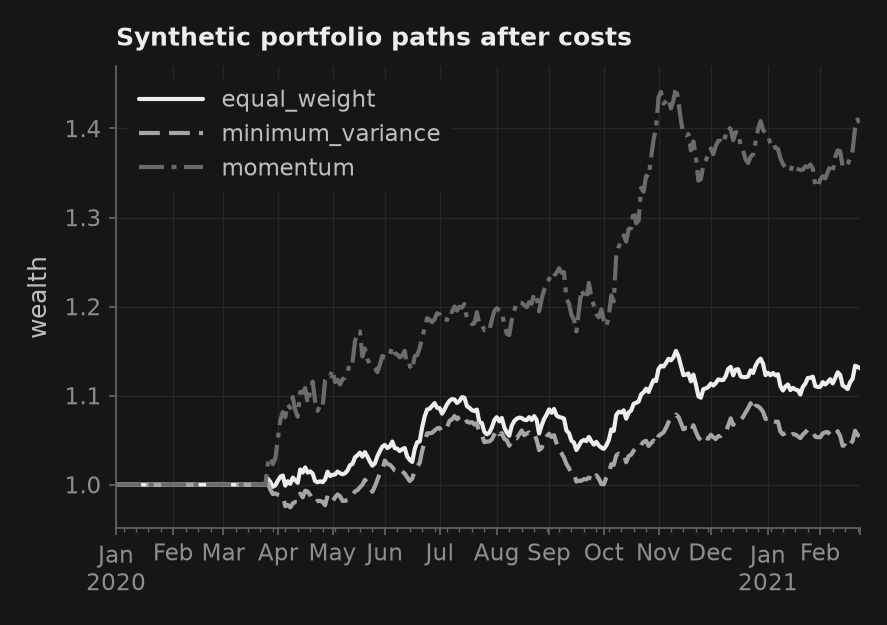

            gross_return  net_return    wealth  turnover  cost   cash_weight  \
2021-02-22     -0.004486   -0.004486  1.055752       0.0   0.0  1.110223e-16   
2021-02-23     -0.001867   -0.001867  1.053781       0.0   0.0  0.000000e+00   

            accounting_residual  
2021-02-22                  0.0  
2021-02-23                  0.0  


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from puremacro import asset_pricing as ap

rng = np.random.default_rng(20261101)
dates = pd.date_range("2020-01-01", periods=300, freq="B")
returns = pd.DataFrame(
    rng.normal([.0002, .0003, .0001], [.008, .014, .006], (300, 3)),
    index=dates, columns=["equity_a", "equity_b", "bond"])
prices = 100 * (1 + returns).cumprod()

def minimum_variance(history):
    covariance = ap.estimate_covariance(history, method="ledoit_wolf")
    return ap.optimize_portfolio(covariance, max_weight=.7).as_series()

policies = {
    "equal_weight": lambda history: ap.equal_weight(history.columns),
    "minimum_variance": minimum_variance,
}
targets = {name: ap.walk_forward_weights(
    returns, policy, min_history=60, window=120, rebalance_every=20)
    for name, policy in policies.items()}
targets["momentum"] = ap.walk_forward_weights(
    prices, lambda history: ap.momentum_weights(history, lookback=40, top_n=2),
    min_history=60, window=120, rebalance_every=20)
runs = {name: ap.backtest_portfolio(returns, weights, cost_bps=15)
        for name, weights in targets.items()}
wealth = pd.DataFrame({name: run.ledger.wealth for name, run in runs.items()})
ax = wealth.plot(title="Synthetic portfolio paths after costs", ylabel="wealth")
display(ax.figure)
plt.close(ax.figure)
print(runs["minimum_variance"].ledger.tail(2))

The portfolio starts in cash. Target rows are complete weights or entirely NaN
(no rebalance); weights are nonnegative and sum to at most one. The residual is
cash. Holdings drift between rebalances. Purchases and sales each pay `cost_bps`
on the risky notional; the cash leg pays no fee. For current risky weights **v**,
post-cost targets **w**, and cost rate **c**, the engine solves
`q + c * sum(abs(q*w - v)) = 1`. Wealth after trading is **q** times pretrade
wealth. This avoids funding both the target holdings and fees from the same cash.

`ledger` reports net returns, wealth, turnover, cost, cash weight and accounting
residual. Turnover and cost are fractions of pretrade wealth. `weights` are
post-cost/pre-return weights; `trades` are signed risky notionals divided by
pretrade wealth. `gross_return` describes the return on those same post-cost
holdings, not a separately simulated zero-cost strategy.

Missing returns are allowed only for assets with zero exposure. A missing held
return, an ineligible exposure or exhausted wealth raises. A boolean `eligibility`
frame must be known at the start of each interval. Supply actual delisting
returns, corporate-action adjustments and timely liquidation decisions; the
engine neither invents prices nor reconstructs a survivor-free universe.
Asset and cash returns must already use a common portfolio currency; no FX
conversion occurs. Include dividends and other distributions in supplied total
returns when those belong in the evaluation.
`walk_forward_weights` restricts the history passed to the callback, but cannot
inspect a callback's external state or certify externally supplied targets.

In [3]:
record = runs["minimum_variance"].to_json()
replayed = ap.replay_backtest(record)
pd.testing.assert_frame_equal(replayed.ledger, runs["minimum_variance"].ledger)
print("Input checksum:", replayed.input_sha256)

Input checksum: 6faed154df4e54943e1d112b806e46c8cfb81465187237f871f8d802413aa5b3


Replay retains dated inputs, calendar/timezone, targets, eligibility and costs.
Custom holiday calendars retain their exact observed dates, not a reusable
pandas frequency rule.
It never stores executable callbacks. The checksum detects accidental input
changes; it is not authentication or a code-version pin. Record the installed
PureMacro version and environment alongside the recipe. Result attributes are
frozen, but pandas display frames remain mutable; their edits do not alter the
saved input recipe.

## Allocation and honest comparison

`estimate_covariance` offers sample covariance (T−1 divisor) and Ledoit–Wolf
shrinkage toward `trace(S)/N * I` (T divisor). No observations are dropped.
Sample means are descriptive: the allocator uses them only if the caller
explicitly passes them as `expected_returns`.

`optimize_portfolio` minimizes
`risk_aversion/2 * w' Sigma w - return_reward * mu'w + turnover_penalty * ||w-w_prev||1`
subject to full investment, nonnegative weights, per-asset caps and an optional
return floor. The L1 penalty uses auxiliary linear constraints. An independent
linear-program gradient bound checks the candidate's convex objective gap.
Infeasible or uncertified solves raise. The reported `optimality_gap` is in
objective units; acceptance compares the normalized gap and constraint violation
to `tolerance`. There is no silent equal-weight fallback or covariance ridge.
A negative final portfolio variance raises, even when a small negative
eigenvalue falls within the eigendecomposition's roundoff tolerance.

`previous_weights` should be the actual pretrade weights if the intention is to
penalize turnover from current holdings. An allocation penalty does not replace
execution fees in the historical ledger. Moments, return targets and penalties
must use consistent period units. `efficient_frontier` takes explicit return
floors; floors below the minimum-variance return repeat that portfolio.

In [4]:
covariance = ap.estimate_covariance(returns.iloc[:150])
frontier = ap.efficient_frontier(
    covariance, expected_returns=np.array([.0002, .0003, .0001]),
    targets=[.00012, .00018, .00024], max_weight=.7)
print(frontier.round(6))

# The candidate family and all parameters above are fixed before this sample.
net = pd.DataFrame({name: run.ledger.net_return for name, run in runs.items()})
evaluation = net.iloc[150:]
comparison = ap.compare_strategies(
    evaluation[["minimum_variance", "momentum"]], evaluation.equal_weight,
    block_length=10, n_boot=499, seed=7)
print(comparison.to_dataframe())
print("Global max-test p-value:", comparison.global_pvalue)
print(ap.risk_summary(evaluation, periods_per_year=252).summary())

   target_return  expected_return  volatility  optimality_gap  \
0        0.00012         0.000159    0.004856             0.0   
1        0.00018         0.000180    0.005050             0.0   
2        0.00024         0.000240    0.007193             0.0   

   weight:equity_a  weight:equity_b  weight:bond  
0         0.331284         0.128605     0.540111  
1         0.393241         0.203380     0.403380  
2         0.568998         0.415501     0.015501  
           strategy  mean_difference  ci_lower_pointwise  ci_upper_pointwise  \
0  minimum_variance        -0.000422           -0.000866            0.000036   
1          momentum         0.000769           -0.000304            0.001671   

   pvalue_max_test  
0             1.00  
1             0.09  
Global max-test p-value: 0.09
Risk summary (T = 150, 252 periods/year, Sharpe se: Lo (2002) HAC, Bartlett lags = 4)
  name             mean      vol   Sharpe     (se)  Sortino   maxDD   dur
  equal_weight   0.1178   0.0871    1.356

The comparison uses paired circular blocks, preserving cross-strategy dependence.
Its one-sided, nonstudentized, centered max statistic tests whether any supplied
candidate improves arithmetic mean net return over the benchmark. The Monte
Carlo correction is `(exceedances+1)/(B+1)`. The p-values cover the supplied family;
the intervals are **pointwise**, not simultaneous. Stationarity and suitable weak
dependence are assumptions, not tested guarantees. Include every configuration
searched on the evaluation sample. Omitted tuning attempts, regime shifts and
unrecorded costs are not corrected by this procedure. The illustrative split is
synthetic, not an independent empirical confirmation.

## Technical indicators

In [5]:
indicators = ap.technical_indicators(prices)
print(indicators["equity_a"][["rsi", "macd", "momentum"]].tail(3))

indicator         rsi      macd  momentum
2021-02-19  35.921433 -1.032568 -0.035163
2021-02-22  29.264648 -1.121650 -0.048224
2021-02-23  32.222004 -1.153966 -0.051117


Outputs use `(asset, indicator)` columns and retain warm-up NaNs. SMA and EMA use
data through the current close. EMA starts with a simple mean and then uses
`alpha=2/(span+1)`. MACD subtracts independently initialized fast and slow EMAs;
its signal begins with the first complete mean of valid MACD values. Vendor
initialization conventions can differ. RSI uses Wilder's `alpha=1/period` and
defines a flat series as 50. Bollinger bands use population standard deviation
(`ddof=0`). Breakout highs/lows exclude the current close. `momentum_weights`
requires a complete positive trailing price window, resolves ties by asset name,
and returns cash if no asset has positive momentum. Signals are observations,
not evidence of predictability; the backtester supplies their execution lag.

## Fundamentals available at the valuation date

In [6]:
facts = pd.DataFrame({
    "asset": ["example", "example"], "metric": ["free_cash_flow"] * 2,
    "unit": ["USD_millions"] * 2, "period_type": ["annual"] * 2,
    "period_start": ["2019-01-01"] * 2, "period_end": ["2019-12-31"] * 2,
    "available_at": ["2020-03-01", "2021-03-01"], "value": [100., 80.],
    "source": ["original_filing", "restatement"],
})
historical = ap.fundamentals_asof(facts, "2020-04-01")
print(historical[["asset", "value", "available_at", "source"]])

# Forecast growth is an explicit analyst assumption, not inferred from two filings.
cash_flows = historical.value.iloc[0] * 1.04 ** np.arange(1, 6)
valuation = ap.discounted_cash_flow(
    cash_flows, .10, terminal_growth=.02, kind="firm",
    net_debt=200, shares_outstanding=10)
print(valuation.summary())
sensitivity = ap.valuation_sensitivity(
    cash_flows, [.08, .10, .12], [.01, .02, .03],
    net_debt=200, shares_outstanding=10)
print(sensitivity)
print("Dividend value per share:", ap.dividend_discount(2., .10, .03).value_per_share)

     asset  value              available_at           source
0  example  100.0 2020-03-01 00:00:00+00:00  original_filing
           metric       value
 enterprise_value 1387.087374
     equity_value 1187.087374
  value_per_share  118.708737
      forecast_pv  423.894068
      terminal_pv  963.193306
terminal_fraction    0.694400
   discount_rate  terminal_growth  value_per_share  terminal_fraction status
0           0.08             0.01       144.184692           0.727677     ok
1           0.08             0.02       165.476983           0.758939     ok
2           0.08             0.03       195.286190           0.792317     ok
3           0.10             0.01       107.167205           0.666664     ok
4           0.10             0.02       118.708737           0.694400     ok
5           0.10             0.03       133.547850           0.723934     ok
6           0.12             0.01        83.640742           0.611610     ok
7           0.12             0.02        90.669877  

Each fact identifies asset, metric, unit, period type, period end, availability
time and value; duration facts also need `period_start`. Types are `instant`,
`quarterly`, `annual` and `ttm`. Selection first finds the latest available
revision for each exact interval, then the latest period within each
asset/metric/unit/type. A later restatement of an older year never displaces the
latest year's observation. Naive times mean UTC; a date-only cutoff means
midnight. Units and period types remain separate. Ambiguous durations raise.
The function preserves supplied provenance but does not validate a source,
normalize SEC taxonomies, convert YTD into quarters or construct TTM.

DCF discounts end-of-period cash flows. `kind="firm"` means FCFF discounted at
WACC, followed by subtraction of supplied net debt. `"equity"` means FCFE at the
cost of equity, and `"dividend"` means total dividends at the cost of equity;
neither subtracts debt again. Rate vectors compound period by period. Terminal
growth uses the final discount rate permanently and must satisfy `-1 < g < r`.
Flows, rates and shares must use consistent currency, inflation, scale and period
units. The example uses monetary amounts and shares in millions.

`terminal_fraction` shows dependence on terminal value; scenario grids are not
probability intervals. Invalid rate-growth pairs remain visible with a status.
Negative equity values remain visible. `fundamental_ratios` computes common
multiples, margins and FCF yield from explicit comparable inputs; nonpositive
valuation denominators produce NaN and a status, not spurious cheapness. Capex
is a positive outflow. EV is market cap + debt − cash, with no inferred minority
or preferred-equity adjustments; ROE uses supplied book equity, not its average.

## Chartists and fundamentalists in an economic model

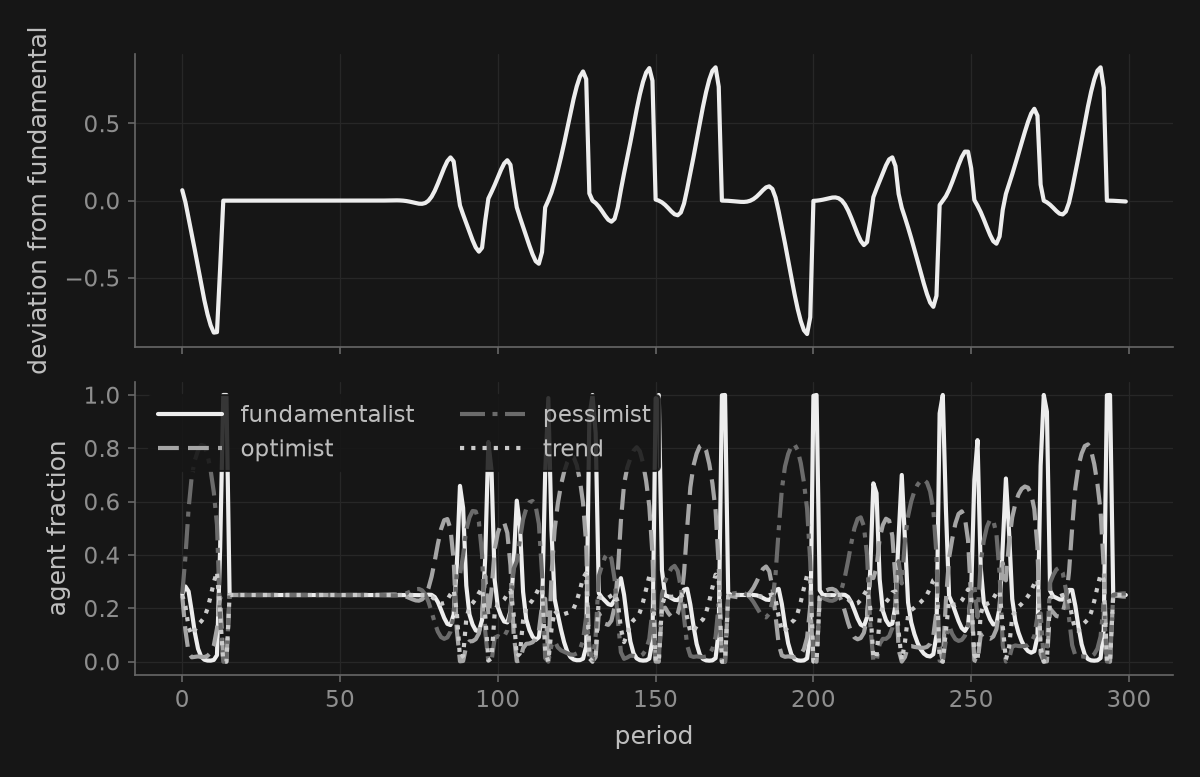

     period  deviation      price  shock_rhs  positive_price  \
298     298  -0.004403  99.995597        0.0            True   
299     299  -0.005492  99.994508        0.0            True   

     fraction:fundamentalist  forecast:fundamentalist  profit:fundamentalist  \
298                 0.249952                      0.0              -0.000004   
299                 0.249925                      0.0              -0.000005   

     fitness:fundamentalist  fraction:optimist  ...  profit:optimist  \
298               -0.000004           0.244220  ...        -0.000273   
299               -0.000005           0.243915  ...        -0.000211   

     fitness:optimist  fraction:pessimist  forecast:pessimist  \
298         -0.000273            0.255856           -0.202715   
299         -0.000211            0.256181           -0.203963   

     profit:pessimist  fitness:pessimist  fraction:trend  forecast:trend  \
298          0.000269           0.000269        0.249972       -0.003047   
2

In [7]:
beliefs = ap.simulate_brock_hommes(
    300, slopes=[0., .9, .9, 1.01], biases=[0., .2, -.2, 0.],
    names=["fundamentalist", "optimist", "pessimist", "trend"],
    intensity=90.5, gross_rate=1.01, risk_scale=1., seed=7)
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(beliefs.deviations)
axes[0].set_ylabel("deviation from fundamental")
axes[1].plot(beliefs.fractions, label=beliefs.names)
axes[1].set(xlabel="period", ylabel="agent fraction")
axes[1].legend(ncol=2)
fig.tight_layout()
display(fig)
plt.close(fig)
print(beliefs.to_dataframe().tail(2))

This is the zero-outside-supply Brock–Hommes affine-rule model, with a constant
fundamental value, expected dividend and gross risk-free return **R > 1**:

```text
f[h,t] = g[h] * x[t-1] + b[h]
n[h,t] = softmax(intensity * U[h,t-1])
R*x[t] = sum_h n[h,t]*f[h,t] + shock[t]
profit[h,t] = (x[t]-R*x[t-1]) * (g[h]*x[t-2]+b[h]-R*x[t-1]) / risk_scale - cost[h]
U[h,t] = profit[h,t] + memory*U[h,t-1]
```

Fractions clear the current price; fitness updates afterwards. Initial deviations
are `x[-3], x[-2], x[-1]`; default initial fitness is their realized profit with
prior accumulated fitness zero. `initial_fitness` can override it. `risk_scale`
is the common perceived risk times risk aversion, **not** the simulated shock
variance. Explicit shocks enter the RHS of the clearing equation. `noise_std`
and `seed` provide an alternative reproducible shock sequence.

The parameters illustrate the four-type family described by Hommes; no claim is
made that this initialization reproduces a digitized chaotic path from a figure.
Costs and memory are explicit extensions. A zero-slope, zero-bias rule is a
fundamentalist, not perfect foresight. Divergence raises with the failing period;
prices are never clipped. Negative implied prices are flagged in the table and
must not be silently passed into a positive-price trading workflow. Bounded
simulation output establishes neither global stability nor empirical fit.

## Validation and sources

Tests compare accounting with hand calculations and an independent dollar ledger,
allocation with analytical and dense-grid solutions, covariance with an explicit
outer-product reference, indicators with scalar formulas, DCF with independent
present values, and beliefs with a literal scalar recurrence. Future-data,
filing-revision and future-shock perturbations test information timing. The
[validation record](../docs/investment_research_validation.md) distinguishes these checks
from empirical replication, browser execution and release acceptance.

- Ledoit and Wolf (2004), [identity-target covariance shrinkage](https://www.ledoit.net/ole1_abstract.htm).
- TA-Lib's [RSI implementation](https://github.com/TA-Lib/ta-lib/blob/main/src/ta_func/ta_RSI.c)
  is a primary reference for Wilder smoothing; flat-series and EMA conventions
  above are explicit PureMacro choices.
- Damodaran's [valuation teaching materials](https://pages.stern.nyu.edu/~adamodar/New_Home_Page/lectures/val.html)
  distinguish firm, equity and dividend valuation.
- The SEC's [EDGAR API documentation](https://www.sec.gov/search-filings/edgar-application-programming-interfaces)
  describes a possible source adapter; no live SEC connector is implemented here.
- Brock and Hommes (1998), [Heterogeneous beliefs and routes to chaos](https://dare.uva.nl/id/6dd1e171-9295-4300-a4d3-a4cf0144d2ac).
  The implemented timing follows equations 104–111, pp. 48–50 of
  [Hommes's author manuscript](https://cendef.uva.nl/binaries/content/assets/subsites/amsterdam-school-of-economics/amsterdam-school-of-economics-research-institute/cendef/working-papers-2005/chhomwechap2006.pdf).

## Exercises

1. Increase trading costs and compare net wealth.
2. Move a filing date beyond the valuation date.
3. Change the switching intensity while keeping the shock path fixed.
4. Record all configurations before evaluating held-out returns.